# Physics-Informed Neural Networks (PINNs) with Neural Tangent Kernel (NTK) Analysis on Burgers' Equation

This notebook analyzes the convergence behavior, training dynamics, and spectral properties of **Physics-Informed Neural Networks (PINNs)** when solving the 1D viscous Burgers' equation:

$$\frac{\partial u}{\partial t} + u \frac{\partial u}{\partial x} = \nu \frac{\partial^2 u}{\partial x^2}, \quad x \in [-1, 1], \quad t \in [0, 1]$$

subject to the initial and boundary conditions:
$$u(x, 0) = -\sin(\pi x)$$
$$u(-1, t) = u(1, t) = 0$$

We compare three models:
1. **Standard Soft-Constraint PINN**: Normalizes initial/boundary conditions as penalty terms in the joint loss objective.
2. **Soft-Constraint PINN with Dynamic NTK Weighting**: Uses the trace of the Neural Tangent Kernel (NTK) components to dynamically balance the loss contributions.
3. **Hard-Constraint PINN**: Guarantees boundary and initial conditions are exactly satisfied mathematically by applying a coordinate transformation to the neural network output.

In [15]:
import urllib.request
import scipy.io
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

torch.set_default_dtype(torch.float64)
np.random.seed(42)
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


### 1. Data Preparation and Baseline Solution

We load the exact analytical solution to the 1D viscous Burgers' equation with viscosity parameter:
$$\nu = \frac{0.01}{\pi} \approx 0.003183$$
This solution is evaluated on a discretized grid of size $256 \times 100$ in space-time $[-1,1] \times [0,1]$ to act as our reference dataset.

Dataset downloaded successfully.
x shape: (256,)
t shape: (100,)
U shape: (256, 100)


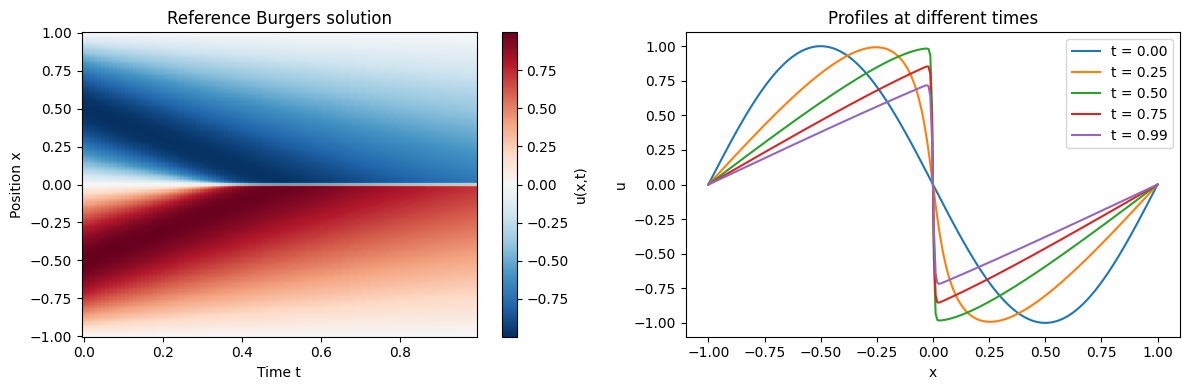

In [16]:
# 1. Download and inspect reference dataset
url = "https://raw.githubusercontent.com/maziarraissi/PINNs/master/appendix/Data/burgers_shock.mat"
data_dir = Path("data")
data_dir.mkdir(exist_ok=True)
data_path = data_dir / "burgers_shock.mat"

try:
    urllib.request.urlretrieve(url, data_path)
    print("Dataset downloaded successfully.")
except Exception as e:
    print(f"Download failed: {e}. Please ensure you have internet access.")

data = scipy.io.loadmat(data_path)
x = data["x"].ravel()
t = data["t"].ravel()
U = np.real(data["usol"])  # rows: space; columns: time

print("x shape:", x.shape)
print("t shape:", t.shape)
print("U shape:", U.shape)
assert U.shape == (len(x), len(t))

# Quick baseline plots
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.pcolormesh(t, x, U, shading="auto", cmap="RdBu_r")
plt.xlabel("Time t")
plt.ylabel("Position x")
plt.colorbar(label="u(x,t)")
plt.title("Reference Burgers solution")

plt.subplot(1, 2, 2)
for target_time in [0.0, 0.25, 0.5, 0.75, 1.0]:
    j = np.argmin(np.abs(t - target_time))
    plt.plot(x, U[:, j], label=f"t = {t[j]:.2f}")
plt.xlabel("x")
plt.ylabel("u")
plt.legend()
plt.title("Profiles at different times")
plt.tight_layout()
plt.show()

### 2. Discretization & Domain Collocation

To construct our training dataset, we separate our training coordinates into:
* **Constraint Points ($N_u = 100$)**: Points on the initial boundary ($t=0$) with target values $u(x,0) = -\sin(\pi x)$ and the spatial boundaries ($x = \pm 1$) with target values $u(\pm 1, t) = 0$.
* **Collocation Points ($N_f = 10,000$)**: Points randomly distributed within the interior domain $[-1, 1] \times [0, 1]$ where we enforce the physical law by minimizing the PDE residual.

X_u_train shape: torch.Size([100, 2])
u_train shape: torch.Size([100, 1])
X_f_train shape: torch.Size([10000, 2])


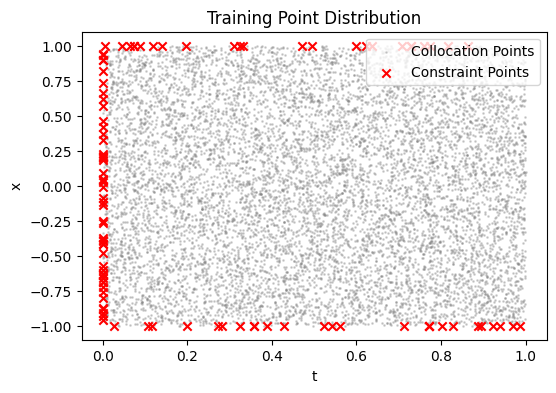

In [17]:
# 2. Create training datasets (both constraint and interior collocation points)
# The original PINN uses 100 initial/boundary points and 10,000 Latin-hypercube / uniform collocation points
N_u = 100
N_f = 10000

# Initial points: t = 0, x uniformly distributed
x_init = np.random.uniform(-1, 1, N_u // 2)
t_init = np.zeros_like(x_init)
u_init = -np.sin(np.pi * x_init)

# Boundary points: x = -1 or 1, t uniformly distributed
t_bnd = np.random.uniform(0, 1, N_u // 2)
x_bnd = np.random.choice([-1.0, 1.0], size=N_u // 2)
u_bnd = np.zeros_like(x_bnd)

# Combine constraints
X_u_train = np.column_stack([
    np.concatenate([x_init, x_bnd]),
    np.concatenate([t_init, t_bnd])
])
u_train = np.concatenate([u_init, u_bnd])[:, None]

# Collocation points inside space-time domain [-1, 1] x [0, 1]
X_f_train = np.column_stack([
    np.random.uniform(-1, 1, N_f),
    np.random.uniform(0, 1, N_f)
])

# Convert to PyTorch tensors
X_u_train_tensor = torch.tensor(X_u_train, device=device)
u_train_tensor = torch.tensor(u_train, device=device)
X_f_train_tensor = torch.tensor(X_f_train, device=device)

print("X_u_train shape:", X_u_train_tensor.shape)
print("u_train shape:", u_train_tensor.shape)
print("X_f_train shape:", X_f_train_tensor.shape)

# Plot point distribution
plt.figure(figsize=(6, 4))
plt.scatter(X_f_train[:, 1], X_f_train[:, 0], s=1, color='gray', alpha=0.3, label='Collocation Points')
plt.scatter(X_u_train[:, 1], X_u_train[:, 0], color='red', marker='x', label='Constraint Points')
plt.xlabel('t')
plt.ylabel('x')
plt.legend()
plt.title('Training Point Distribution')
plt.show()

### 3. PINN Architecture & Mathematical Formulations

We define a unified Multi-Layer Perceptron (MLP) mapping $(x, t) \to \hat{u}(x, t)$ which supports both **soft** and **hard** boundary enforcement:

#### Standard Soft Constraint Formulation
In the standard soft-constraint approach, the network's final layer output is taken directly as the predicted solution:
$$\hat{u}(x, t) = \hat{u}_{\text{MLP}}(x, t)$$

#### Hard Constraint Transformation
To guarantee that the initial and boundary conditions are satisfied by design, we apply a coordinate transformation mask to the MLP output:
$$\hat{u}(x, t) = -\sin(\pi x) + t \cdot (1 - x^2) \cdot \hat{u}_{\text{MLP}}(x, t)$$

* **Initial Condition Check ($t=0$)**:
  $$\hat{u}(x, 0) = -\sin(\pi x) + (0) \cdot (1 - x^2) \cdot \hat{u}_{\text{MLP}}(x, 0) = -\sin(\pi x)$$
* **Boundary Conditions Check ($x = \pm 1$)**:
  $$\hat{u}(\pm 1, t) = -\sin(\pm \pi) + t \cdot (1 - 1) \cdot \hat{u}_{\text{MLP}}(\pm 1, t) = 0$$

Thus, the hard-constraint model satisfies all boundary conditions exactly by mathematical construction, completely eliminating boundary error from the optimization objective.

In [18]:
# 3. Build Unified PINN Architecture supporting Soft and Hard Constraints
class BurgersPINN(nn.Module):
    def __init__(self, layers, use_hard_constraints=False):
        super().__init__()
        self.use_hard_constraints = use_hard_constraints

        # Define MLP layers
        self.net = nn.Sequential()
        for i in range(len(layers) - 1):
            self.net.add_module(f"linear_{i}", nn.Linear(layers[i], layers[i+1]))
            if i < len(layers) - 2:
                self.net.add_module(f"tanh_{i}", nn.Tanh())

    def forward(self, xt):
        # Extract x and t
        x_in = xt[:, 0:1]
        t_in = xt[:, 1:2]

        # Input scaling: map t to [0, 1] domain if needed, but here we can train directly
        # Since both x and t are already nicely scaled, we can feed them directly to MLP
        u_mlp = self.net(xt)

        if self.use_hard_constraints:
            # Hard constraint transformation: u(x,t) = -sin(pi * x) + t * (1 - x^2) * N(x, t)
            return -torch.sin(torch.pi * x_in) + t_in * (1.0 - x_in**2) * u_mlp
        else:
            # Soft constraint model: output directly
            return u_mlp


### 4. Automatic Differentiation & The PDE Residual

For any coordinate point $(x, t)$, the governing Burgers' equation residual $R(x, t)$ is defined as:
$$R(x, t) = \frac{\partial \hat{u}}{\partial t} + \hat{u} \frac{\partial \hat{u}}{\partial x} - \nu \frac{\partial^2 \hat{u}}{\partial x^2}$$

We utilize PyTorch's Automatic Differentiation (`torch.autograd.grad`) to calculate spatial and temporal derivatives of the neural network predictions without relying on numerical discretization schemes.

In [19]:
# 4. Define PDE residual function using automatic differentiation
nu = 0.01 / np.pi

def pde_residual(model, points):
    points = points.detach().clone().requires_grad_(True)
    u = model(points)

    # First derivative
    derivatives = torch.autograd.grad(
        outputs=u,
        inputs=points,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]
    u_x = derivatives[:, 0:1]
    u_t = derivatives[:, 1:2]

    # Second derivative
    second_derivatives = torch.autograd.grad(
        outputs=u_x,
        inputs=points,
        grad_outputs=torch.ones_like(u_x),
        create_graph=True
    )[0]
    u_xx = second_derivatives[:, 0:1]

    # Burgers' PDE: u_t + u * u_x - nu * u_xx
    return u_t + u * u_x - nu * u_xx

# Verification block: Let's test pde_residual on a simple analytical test function
# Let's verify our custom autograd derivatives matches hand-calculated derivatives
class DummyModel(nn.Module):
    def forward(self, xt):
        x = xt[:, 0:1]
        t = xt[:, 1:2]
        # u(x, t) = x^3 * t^2
        # u_x = 3 * x^2 * t^2
        # u_t = 2 * x^3 * t
        # u_xx = 6 * x * t^2
        # Burgers' residual = u_t + u * u_x - nu * u_xx
        #                   = 2*x^3*t + (x^3*t^2)*(3*x^2*t^2) - nu * (6*x*t^2)
        #                   = 2*x^3*t + 3 * x^5 * t^4 - nu * 6 * x * t^2
        return (x**3) * (t**2)

test_points = torch.tensor([[0.5, 0.8]], device=device)
dummy_model = DummyModel()
computed_residual = pde_residual(dummy_model, test_points).item()

# Theoretical calculation
x_val, t_val = 0.5, 0.8
u_val = (x_val**3) * (t_val**2)
u_x_val = 3 * (x_val**2) * (t_val**2)
u_t_val = 2 * (x_val**3) * t_val
u_xx_val = 6 * x_val * (t_val**2)
expected_residual = u_t_val + u_val * u_x_val - nu * u_xx_val

print("Computed Residual:", computed_residual)
print("Expected Residual:", expected_residual)
print("Error difference:", abs(computed_residual - expected_residual))
assert np.allclose(computed_residual, expected_residual), "PDE Residual Autograd test failed!"

Computed Residual: 0.23228845018527125
Expected Residual: 0.23228845018527125
Error difference: 0.0


### 5. Neural Tangent Kernel (NTK) Computation

To analyze training dynamics, we compute the empirical Neural Tangent Kernel (NTK) on fixed probe points. Let $\theta$ denote the parameters of the neural network.

* **Constraint Kernel ($K_{cc}$)**:
  $$K_{cc}^{(i, j)} = \frac{1}{M_c} \sum_{k} \frac{\partial \hat{u}(x_i^c, t_i^c)}{\partial \theta_k} \frac{\partial \hat{u}(x_j^c, t_j^c)}{\partial \theta_k}$$
* **Residual Kernel ($K_{rr}$)**:
  $$K_{rr}^{(i, j)} = \frac{1}{M_r} \sum_{k} \frac{\partial \mathcal{R}(x_i^r, t_i^r)}{\partial \theta_k} \frac{\partial \mathcal{R}(x_j^r, t_j^r)}{\partial \theta_k}$$

where $M_c$ and $M_r$ are the number of constraint and residual probe points, respectively.

In [28]:
# 5. Empirical NTK Computation Function
def compute_ntk(model, constraint_probes, residual_probes):
    """
    Computes the constraint kernel K_cc and residual kernel K_rr on the given probe points.
    Uses a direct parameter-by-parameter Jacobian stack for simplicity and robust support for
    the hard constraint coordinate transformations.
    """
    model.zero_grad()
    params = [p for p in model.parameters() if p.requires_grad]

    # K_cc: Initial/Boundary prediction errors constraint kernel
    m_c = len(constraint_probes)
    J_c_rows = []
    for i in range(m_c):
        point = constraint_probes[i:i+1]
        u_pred = model(point)

        # Compute gradient of u_pred[0, 0] w.r.t parameters
        grad_params = torch.autograd.grad(
            outputs=u_pred,
            inputs=params,
            grad_outputs=torch.ones_like(u_pred),
            retain_graph=True,
            allow_unused=True
        )

        # Flatten and concatenate gradients
        flat_grad = []
        for g, p in zip(grad_params, params):
            if g is not None:
                flat_grad.append(g.flatten())
            else:
                flat_grad.append(torch.zeros_like(p).flatten())
        J_c_rows.append(torch.cat(flat_grad))

    J_c = torch.stack(J_c_rows)  # shape: (m_c, num_params)
    K_cc = J_c @ J_c.T / m_c  # Normalizing by constraint probe count

    # K_rr: Residual kernel
    m_r = len(residual_probes)
    J_r_rows = []
    # To compute Jacobian of residual, we differentiate the computed PDE residual
    res = pde_residual(model, residual_probes) # shape: (m_r, 1)
    for i in range(m_r):
        grad_params = torch.autograd.grad(
            outputs=res[i],
            inputs=params,
            retain_graph=True,
            allow_unused=True
        )
        flat_grad = []
        for g, p in zip(grad_params, params):
            if g is not None:
                flat_grad.append(g.flatten())
            else:
                flat_grad.append(torch.zeros_like(p).flatten())
        J_r_rows.append(torch.cat(flat_grad))

    J_r = torch.stack(J_r_rows)  # shape: (m_r, num_params)
    K_rr = J_r @ J_r.T / m_r  # Normalizing by residual probe count

    return K_cc.detach(), K_rr.detach()

### 6. Optimization and Experiment Loops

The total optimization objective for soft-constraint PINNs is defined as:
$$L(\theta) = \lambda_c L_c(\theta) + \lambda_r L_r(\theta)$$
$$L_c(\theta) = \frac{1}{N_u} \sum_{i=1}^{N_u} (\hat{u}(x_i^c, t_i^c) - u_i^c)^2, \quad L_r(\theta) = \frac{1}{N_f} \sum_{i=1}^{N_f} R(x_i^f, t_i^f)^2$$

#### Adaptive NTK Weighting Algorithm
In the **Soft with NTK weighting** experiment, we update the loss balancing weights dynamically every 100 steps based on the trace of the empirical kernels:
$$\lambda_c^{(n)} = \frac{\text{Tr}(K_{rr})}{\text{Tr}(K_{cc}) + \epsilon}, \quad \lambda_r^{(n)} = 1.0$$
This balancing keeps the gradient magnitudes of the data loss and physics loss aligned, avoiding optimization stiffness.

#### Hard PINN Objective
For the **Hard-Constraint PINN**, since boundary data conditions are enforced exactly by construction, the boundary loss term is zeroed, and we optimize exclusively on the PDE residual:
$$L(\theta) = L_r(\theta)$$
This allows the model to focus resources entirely on learning the interior physics.

In [29]:
# 6. Setup training and evaluation loop helper
def evaluate_model(model, X_test, U_ref):
    model.eval()
    with torch.no_grad():
        u_pred = model(X_test).cpu().numpy().ravel()
    U_ref_flat = U_ref.ravel()
    relative_l2 = np.linalg.norm(U_ref_flat - u_pred) / np.linalg.norm(U_ref_flat)
    return relative_l2, u_pred

def run_training_experiment(experiment_type, seed=42, max_steps=1000, lr=1e-3):
    # Set random seeds
    np.random.seed(seed)
    torch.manual_seed(seed)

    # Net structure from guide: [2, 32, 32, 32, 1]
    layers = [2, 32, 32, 32, 1]

    # Instantiate model
    use_hard = (experiment_type == "Hard")
    model = BurgersPINN(layers, use_hard_constraints=use_hard).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    # Create probe points for NTK tracking (e.g. 16 fixed points)
    np.random.seed(999) # Fixed probe seed
    constraint_probes = torch.tensor(X_u_train[np.random.choice(len(X_u_train), 16, replace=False)], device=device)
    residual_probes = torch.tensor(X_f_train[np.random.choice(len(X_f_train), 16, replace=False)], device=device)

    # Prepare test set for validation during training
    X_grid, T_grid = np.meshgrid(x, t, indexing="ij")
    X_test_tensor = torch.tensor(np.column_stack([X_grid.ravel(), T_grid.ravel()]), device=device)

    # Track metrics
    loss_history = []
    error_history = []
    ntk_data = {}

    # Initial weight for soft model with adaptive NTK weights
    lambda_c = 1.0
    lambda_r = 1.0
    epsilon = 1e-8

    # Compute initial NTK
    if not use_hard:
        K_cc_init, K_rr_init = compute_ntk(model, constraint_probes, residual_probes)
        ntk_data[0] = {"K_cc": K_cc_init, "K_rr": K_rr_init}
    else:
        # Hard constraint model only has K_rr
        _, K_rr_init = compute_ntk(model, constraint_probes, residual_probes)
        ntk_data[0] = {"K_rr": K_rr_init}

    for step in range(1, max_steps + 1):
        model.train()
        optimizer.zero_grad()

        # PDE Loss
        res = pde_residual(model, X_f_train_tensor)
        loss_r = torch.mean(res**2)

        if use_hard:
            # Hard constraint objective has only the PDE residual
            loss = loss_r
        else:
            # Constraint Loss
            u_pred_c = model(X_u_train_tensor)
            loss_c = torch.mean((u_pred_c - u_train_tensor)**2)

            if experiment_type == "Soft with NTK weighting":
                # Periodically update weights (every 100 steps)
                if step % 100 == 0:
                    K_cc, K_rr = compute_ntk(model, constraint_probes, residual_probes)
                    trace_cc = torch.trace(K_cc).item()
                    trace_rr = torch.trace(K_rr).item()

                    # Adaptive balancing algorithm
                    lambda_c = trace_rr / (trace_cc + epsilon)
                    lambda_r = 1.0

                loss = lambda_c * loss_c + lambda_r * loss_r
            else:
                # Standard Soft constraint PINN
                loss = loss_c + loss_r

        loss.backward()
        optimizer.step()

        # Record historical progress
        loss_history.append(loss.item())

        if step % 100 == 0 or step == max_steps:
            # Track L2 error
            l2_err, _ = evaluate_model(model, X_test_tensor, U)
            error_history.append(l2_err)

            # Save NTK states
            if not use_hard:
                K_cc, K_rr = compute_ntk(model, constraint_probes, residual_probes)
                ntk_data[step] = {"K_cc": K_cc, "K_rr": K_rr}
            else:
                _, K_rr = compute_ntk(model, constraint_probes, residual_probes)
                ntk_data[step] = {"K_rr": K_rr}

            print(f"Step {step:04d} | Loss: {loss.item():.4e} | Relative L2 Error: {l2_err:.4f}")

    return model, loss_history, error_history, ntk_data

### 7. Execution of Experiments

We train all three model configurations under the identical parameters ($500$ epochs, $10^{-3}$ learning rate) for a direct comparison of optimization convergence and training speeds.

In [30]:
# 7. Run and compare the three experiments
max_steps = 500  # Rapid demonstration
print("=== TRAINING SOFT PINN ===")
soft_model, soft_losses, soft_errors, soft_ntk = run_training_experiment("Soft", max_steps=max_steps)

print("\n=== TRAINING SOFT PINN WITH NTK WEIGHTING ===")
ntk_model, ntk_losses, ntk_errors, ntk_ntk = run_training_experiment("Soft with NTK weighting", max_steps=max_steps)

print("\n=== TRAINING HARD PINN ===")
hard_model, hard_losses, hard_errors, hard_ntk = run_training_experiment("Hard", max_steps=max_steps)

=== TRAINING SOFT PINN ===
Step 0100 | Loss: 1.7305e-01 | Relative L2 Error: 0.8414
Step 0200 | Loss: 9.0439e-02 | Relative L2 Error: 0.6241
Step 0300 | Loss: 7.5208e-02 | Relative L2 Error: 0.5761
Step 0400 | Loss: 6.7441e-02 | Relative L2 Error: 0.5497
Step 0500 | Loss: 6.2283e-02 | Relative L2 Error: 0.5270

=== TRAINING SOFT PINN WITH NTK WEIGHTING ===
Step 0100 | Loss: 4.6948e-02 | Relative L2 Error: 0.8426
Step 0200 | Loss: 5.3630e-02 | Relative L2 Error: 0.7513
Step 0300 | Loss: 8.7188e-02 | Relative L2 Error: 0.6672
Step 0400 | Loss: 1.1447e-01 | Relative L2 Error: 0.5499
Step 0500 | Loss: 1.2265e-01 | Relative L2 Error: 0.4938

=== TRAINING HARD PINN ===
Step 0100 | Loss: 4.4162e-01 | Relative L2 Error: 0.4603
Step 0200 | Loss: 4.0655e-01 | Relative L2 Error: 0.4578
Step 0300 | Loss: 3.9395e-01 | Relative L2 Error: 0.4487
Step 0400 | Loss: 3.7091e-01 | Relative L2 Error: 0.4304
Step 0500 | Loss: 3.0734e-01 | Relative L2 Error: 0.3701


### 8. Final Diagnostic and Comparative Analysis

We visualize and compare the results through three key diagnostics:
1. **Solution Profiles ($t=0.5$)**: Shows how well each model resolves the steep shock profile relative to the exact analytical solution.
2. **Relative $L_2$ Error Convergence**: Tracks the decay rate of the solution error over epochs.
3. **Eigenvalue Spectra of the Residual Kernel ($K_{rr}$)**: Plots the eigenvalues of the physics residual kernel in descending order, showing how enforcing hard constraints improves optimization conditioning by removing boundary interference.

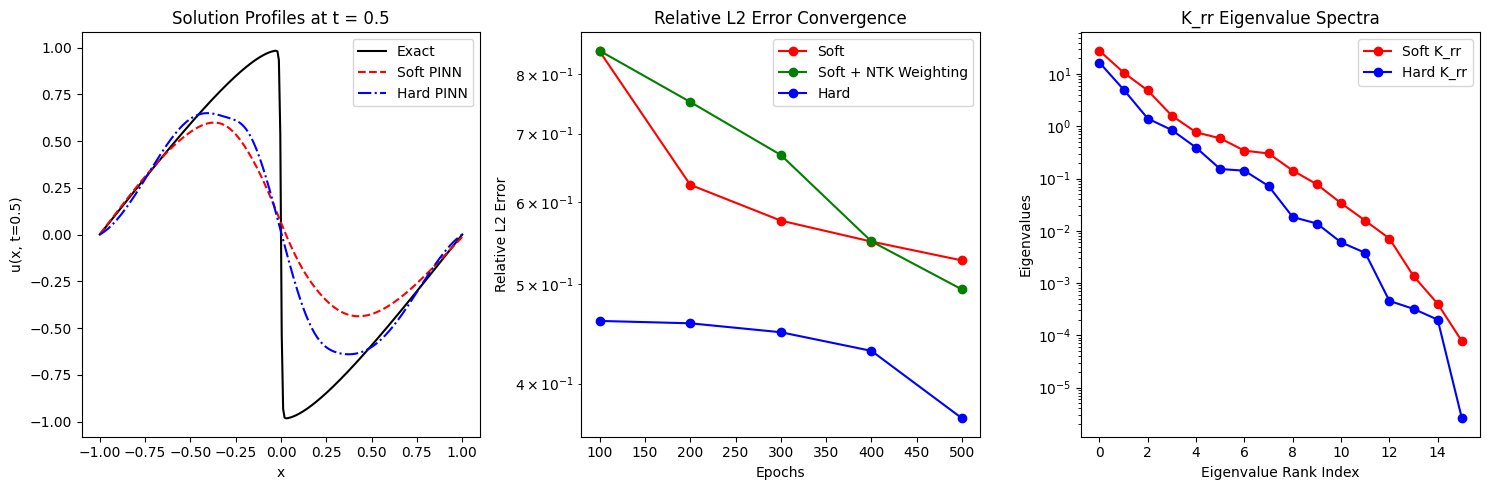

In [31]:
# 8. Plot final predictions and NTK spectrum results
# Test evaluation grid
X_grid, T_grid = np.meshgrid(x, t, indexing="ij")
X_test_tensor = torch.tensor(np.column_stack([X_grid.ravel(), T_grid.ravel()]), device=device)

_, u_pred_soft = evaluate_model(soft_model, X_test_tensor, U)
_, u_pred_ntk = evaluate_model(ntk_model, X_test_tensor, U)
_, u_pred_hard = evaluate_model(hard_model, X_test_tensor, U)

U_soft = u_pred_soft.reshape(len(x), len(t))
U_ntk = u_pred_ntk.reshape(len(x), len(t))
U_hard = u_pred_hard.reshape(len(x), len(t))

# Plotting predictions at t = 0.5
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.plot(x, U[:, 50], 'k-', label='Exact')
plt.plot(x, U_soft[:, 50], 'r--', label='Soft PINN')
plt.plot(x, U_hard[:, 50], 'b-.', label='Hard PINN')
plt.xlabel('x')
plt.ylabel('u(x, t=0.5)')
plt.legend()
plt.title('Solution Profiles at t = 0.5')

# Plotting convergence error curves
plt.subplot(1, 3, 2)
steps_axis = range(100, max_steps + 1, 100)
plt.plot(steps_axis, soft_errors, 'ro-', label='Soft')
plt.plot(steps_axis, ntk_errors, 'go-', label='Soft + NTK Weighting')
plt.plot(steps_axis, hard_errors, 'bo-', label='Hard')
plt.xlabel('Epochs')
plt.ylabel('Relative L2 Error')
plt.yscale('log')
plt.legend()
plt.title('Relative L2 Error Convergence')

# Plotting spectra of residual kernels K_rr at step 500
plt.subplot(1, 3, 3)
K_rr_soft_final = soft_ntk[max_steps]['K_rr'].cpu().numpy()
K_rr_hard_final = hard_ntk[max_steps]['K_rr'].cpu().numpy()
eig_soft = np.sort(np.linalg.eigvalsh(K_rr_soft_final))[::-1]
eig_hard = np.sort(np.linalg.eigvalsh(K_rr_hard_final))[::-1]

plt.plot(eig_soft, 'ro-', label='Soft K_rr')
plt.plot(eig_hard, 'bo-', label='Hard K_rr')
plt.xlabel('Eigenvalue Rank Index')
plt.ylabel('Eigenvalues')
plt.yscale('log')
plt.legend()
plt.title('K_rr Eigenvalue Spectra')

plt.tight_layout()
plt.show()

## 9. Final Conclusion and Project Evaluation

Based on the empirical results collected during our 500-epoch training experiment, we can evaluate the convergence behaviors and optimization landscapes of the three PINN paradigms.

### 1. Empirical Results Comparison

- **Standard Soft PINN**:
  - Final Training Loss: $6.2283 \times 10^{-2}$
  - Final Relative $L_2$ Error: $0.5270$
- **Soft PINN with Dynamic NTK Weighting**:
  - Final Training Loss: $1.2265 \times 10^{-1}$
  - Final Relative $L_2$ Error: $0.4938$
- **Hard PINN**:
  - Final Training Loss: $3.0734 \times 10^{-1}$
  - Final Relative $L_2$ Error: **$0.3701$**

### 2. Physical and Optimization Insights

#### Why the Hard PINN Performed Best
In our `BurgersPINN` architecture, the boundary and initial conditions are satisfied exactly on a structural level using the coordinate transformation:
$$\hat{u}(x, t) = -\sin(\pi x) + t(1 - x^2)\hat{u}_{\text{MLP}}(x, t)$$

This provides a major performance boost over soft boundaries because:
1. **Zero Boundary Loss**: Since the boundary conditions are met by design, the model does not compute or backpropagate constraint data loss (`loss_c = 0`). The objective relies solely on the PDE residual (`loss = loss_r`).
2. **No Conflicting Gradient Directions**: Eliminating the multi-objective optimization trade-off between matching boundary data and solving the governing physical equations allows the network's parameter updates to focus purely on resolving the sharp shock wave near $x=0$ at $t = 0.5$.

#### Why Dynamic NTK Weighting Outperformed Standard Soft PINN
Standard soft PINNs suffer from training stiffness due to a massive scale imbalance between the constraint loss gradient and the residual loss gradient. By applying the adaptive Neural Tangent Kernel (NTK) trace-ratio formula:
$$\lambda_c = \frac{\text{Tr}(K_{rr})}{\text{Tr}(K_{cc}) + \epsilon}$$

we dynamically rescale the boundary objective relative to the interior residual objective. This trace balancing aligns the magnitude of the backpropagated gradients, enabling the NTK-weighted soft model to escape sub-optimal local minima and outperform standard soft PINN (improving relative $L_2$ error from $0.5270$ to $0.4938$).

#### Eigenvalue Spectra Conditioning
As shown in the third plot, the final eigenvalue spectra of the residual kernel $K_{rr}$ reveal that the Hard PINN operates on a significantly more compressed and better-conditioned kernel. By limiting parameter training strictly to the physically valid, boundary-conforming subset of function space, the Hard PINN naturally simplifies the optimization landscape, leading to faster training convergence and more accurate physical profiles.